# Predicting Employee Attrition Using Machine Learning
**Module:** Mining and Predictive Analytics (COMP 30044) – CW2

**Dataset:** IBM HR Analytics Employee Attrition & Performance (Kaggle)

This notebook follows the **CRISP-DM** methodology:

1. Business Understanding – predict if an employee will leave (Attrition = Yes/No)
2. Data Understanding – dataset description + EDA (Sections 4.2 and 4.3)
3. Data Preparation – cleaning, encoding, scaling (Section 4.4)
4. Modeling – Logistic Regression and Random Forest (Section 4.5)
5. Evaluation – Accuracy, Precision, Recall, F1-score (Section 4.6)
6. Deployment – Streamlit app (`app.py`)

## 0. Import Libraries

In [1]:
import os
import warnings
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_auc_score,
                             roc_curve, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

# folders to save the graphs and the trained model
os.makedirs("figures", exist_ok=True)
os.makedirs("model", exist_ok=True)

RANDOM_STATE = 42

## 4.2 Dataset Description
The dataset was downloaded from Kaggle:
https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset

In [2]:
# load the dataset (utf-8-sig removes a hidden character that some copies of the file have)
df = pd.read_csv("data/WA_Fn-UseC_-HR-Employee-Attrition.csv", encoding="utf-8-sig")

print("Number of rows   :", df.shape[0])
print("Number of columns:", df.shape[1])
df.head()

Number of rows   : 1470
Number of columns: 35


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [3]:
# data types and non-null counts of every column
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [4]:
# summary statistics of the numeric columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0


In [5]:
# the target variable
print(df["Attrition"].value_counts())
print()
print((df["Attrition"].value_counts(normalize=True) * 100).round(2))

Attrition
No     1233
Yes     237
Name: count, dtype: int64

Attrition
No     83.88
Yes    16.12
Name: proportion, dtype: float64


In [6]:
# split the features into numeric and categorical
numeric_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = df.select_dtypes(exclude="number").columns.tolist()

print("Numeric columns (", len(numeric_cols), "):", numeric_cols)
print()
print("Categorical columns (", len(categorical_cols), "):", categorical_cols)

Numeric columns ( 26 ): ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Categorical columns ( 9 ): ['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'Over18', 'OverTime']


## 4.3 Exploratory Data Analysis (EDA)
### 4.3.1 Target distribution

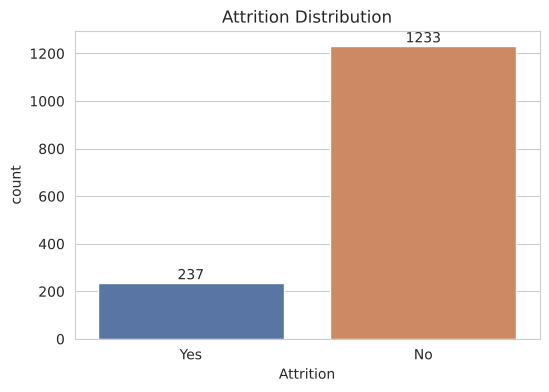

In [7]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(x="Attrition", data=df, palette=["#4C72B0", "#DD8452"])
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.title("Attrition Distribution")
plt.savefig("figures/01_attrition_distribution.png", bbox_inches="tight")
plt.show()

**Interpretation:** Only about 16% of employees left the company, so the data is **imbalanced**.
This means accuracy alone is not a good metric, and we must focus on Recall and F1-score for the "Yes" class.

### 4.3.2 Attrition rate by categorical features

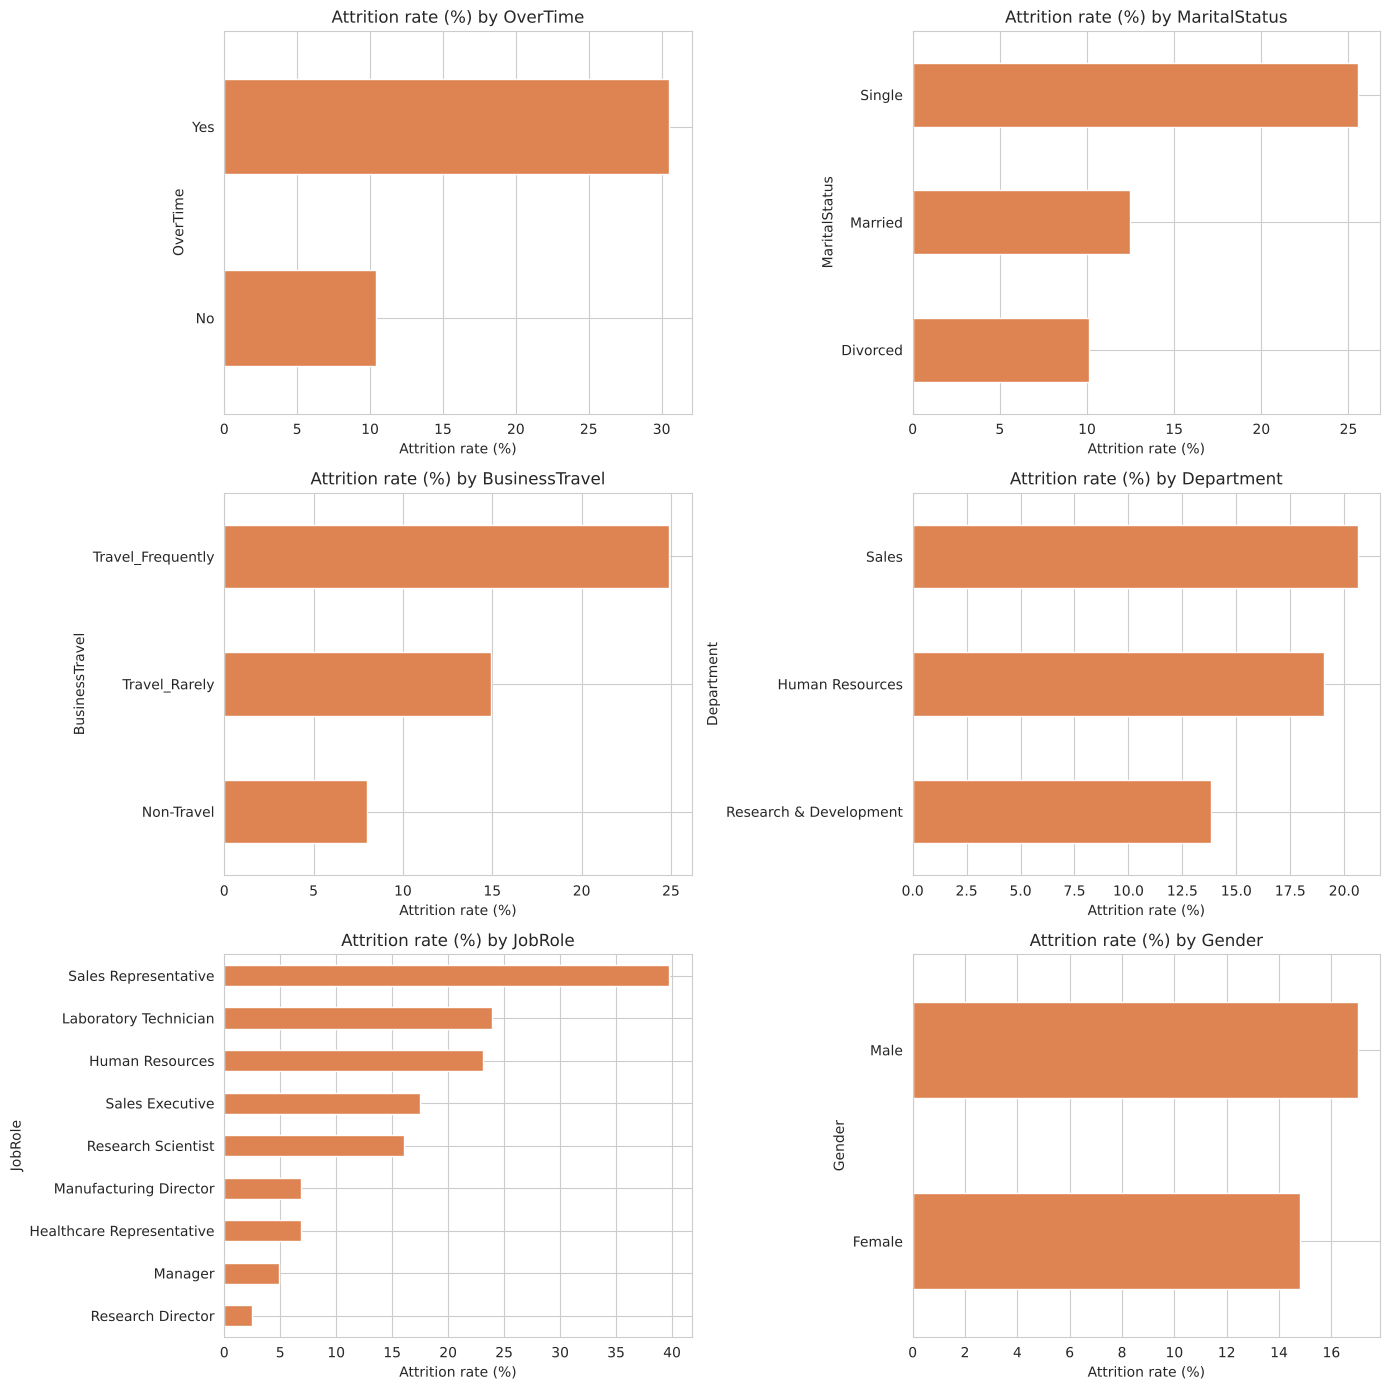

In [8]:
cat_features = ["OverTime", "MaritalStatus", "BusinessTravel", "Department", "JobRole", "Gender"]

fig, axes = plt.subplots(3, 2, figsize=(14, 14))
axes = axes.flatten()

for i, col in enumerate(cat_features):
    # percentage of employees who left in each category
    rate = df.groupby(col)["Attrition"].apply(lambda x: (x == "Yes").mean() * 100).sort_values()
    rate.plot(kind="barh", ax=axes[i], color="#DD8452")
    axes[i].set_title("Attrition rate (%) by " + col)
    axes[i].set_xlabel("Attrition rate (%)")

plt.tight_layout()
plt.savefig("figures/02_attrition_rate_by_category.png", bbox_inches="tight")
plt.show()

In [9]:
# the same numbers as a table
for col in ["OverTime", "MaritalStatus", "BusinessTravel"]:
    print(pd.crosstab(df[col], df["Attrition"], normalize="index").round(3) * 100)
    print()

Attrition    No   Yes
OverTime             
No         89.6  10.4
Yes        69.5  30.5

Attrition        No   Yes
MaritalStatus            
Divorced       89.9  10.1
Married        87.5  12.5
Single         74.5  25.5

Attrition            No   Yes
BusinessTravel               
Non-Travel         92.0   8.0
Travel_Frequently  75.1  24.9
Travel_Rarely      85.0  15.0



**Interpretation:** (write your own after you see the graph) – e.g. employees who work **overtime** leave much more
than those who don't, **single** employees leave more than married ones, and **Sales Representatives** have the highest attrition rate.

### 4.3.3 Distribution of numeric features by attrition (histograms)

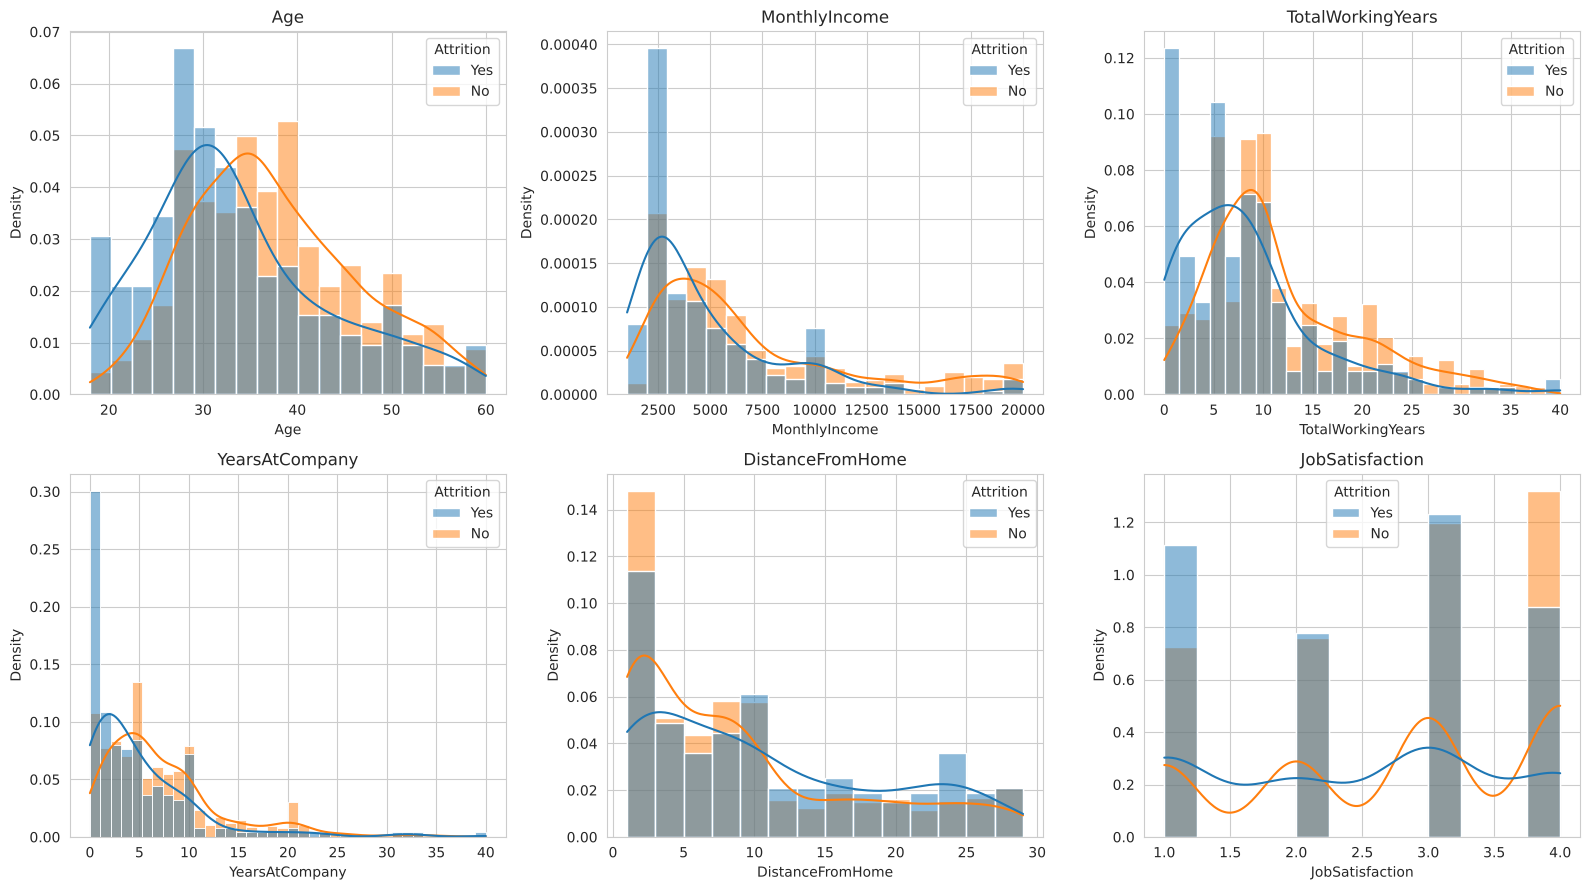

In [10]:
hist_cols = ["Age", "MonthlyIncome", "TotalWorkingYears", "YearsAtCompany", "DistanceFromHome", "JobSatisfaction"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(hist_cols):
    sns.histplot(data=df, x=col, hue="Attrition", kde=True, stat="density",
                 common_norm=False, ax=axes[i])
    axes[i].set_title(col)

plt.tight_layout()
plt.savefig("figures/03_histograms.png", bbox_inches="tight")
plt.show()

### 4.3.4 Boxplots

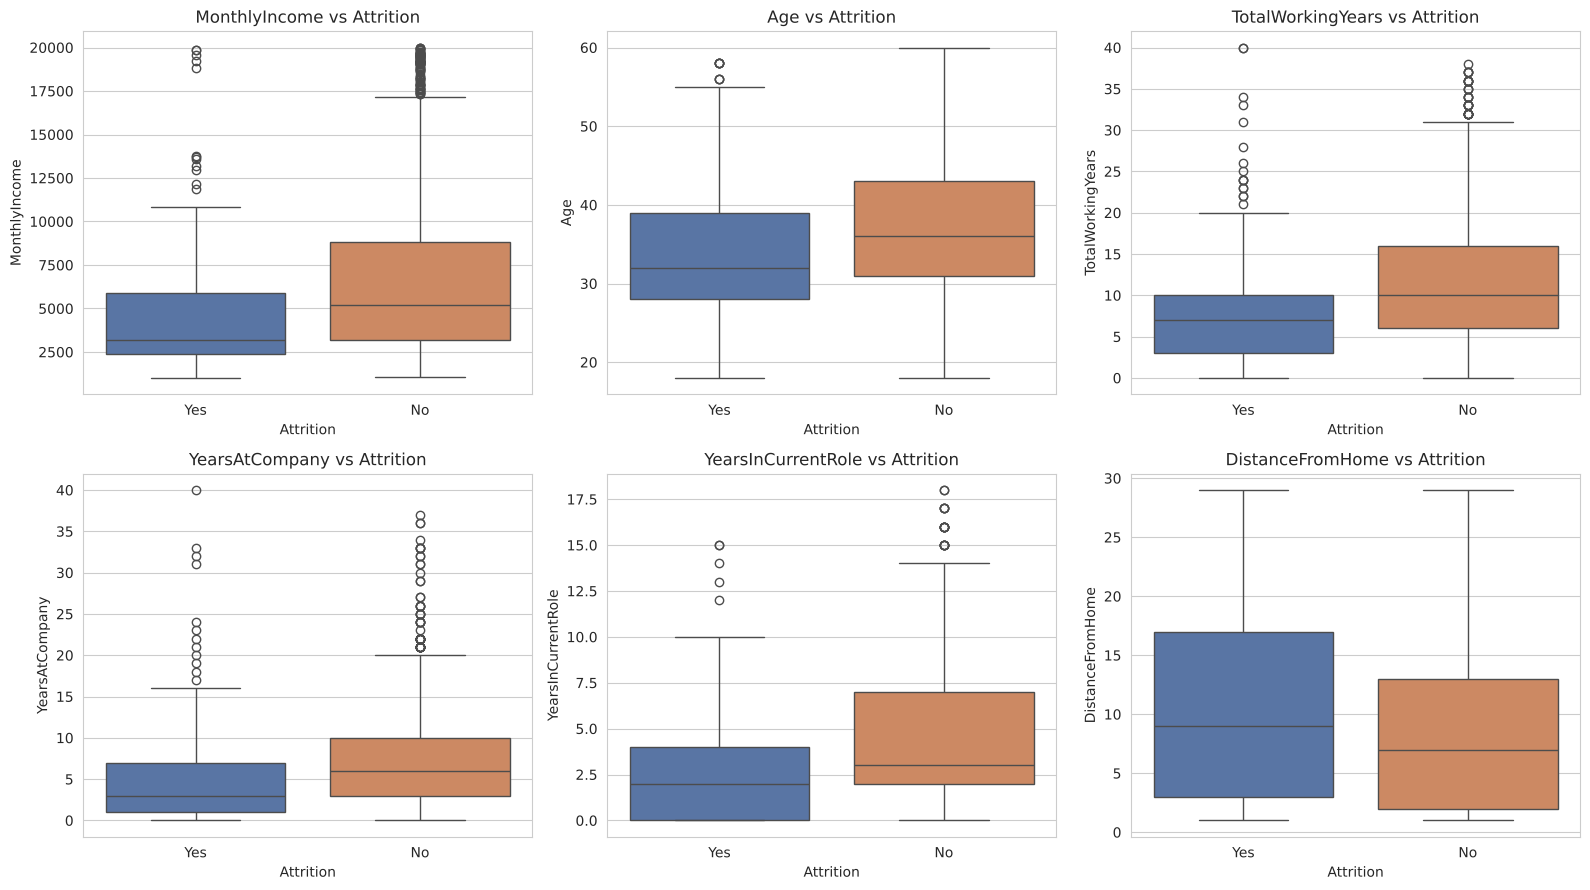

In [11]:
box_cols = ["MonthlyIncome", "Age", "TotalWorkingYears", "YearsAtCompany", "YearsInCurrentRole", "DistanceFromHome"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(box_cols):
    sns.boxplot(x="Attrition", y=col, data=df, ax=axes[i], palette=["#4C72B0", "#DD8452"])
    axes[i].set_title(col + " vs Attrition")

plt.tight_layout()
plt.savefig("figures/04_boxplots.png", bbox_inches="tight")
plt.show()

**Interpretation:** Employees who left have a **lower monthly income**, are **younger**, and have **fewer working years**
than employees who stayed. The boxplots also show many outliers in MonthlyIncome and the "Years" columns (handled in 4.4).

### 4.3.5 Correlation matrix and heatmap

In [12]:
# make a numeric copy of the target so we can include it in the correlation
df_corr = df.copy()
df_corr["Attrition"] = df_corr["Attrition"].map({"Yes": 1, "No": 0})

# remove columns that have only one value (their correlation is NaN)
constant_cols = [c for c in df_corr.columns if df_corr[c].nunique() == 1]
print("Constant columns:", constant_cols)

corr_matrix = df_corr.select_dtypes(include="number").drop(columns=constant_cols, errors="ignore").corr()
corr_matrix.round(2)

Constant columns: ['EmployeeCount', 'Over18', 'StandardHours']


,Age,Attrition,DailyRate,DistanceFromHome,Education,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
Age,1.00,-0.16,0.01,-0.00,0.21,-0.01,0.01,0.02,0.03,0.51,...,0.00,0.05,0.04,0.68,-0.02,-0.02,0.31,0.21,0.22,0.20
Attrition,-0.16,1.00,-0.06,0.08,-0.03,-0.01,-0.10,-0.01,-0.13,-0.17,...,0.00,-0.05,-0.14,-0.17,-0.06,-0.06,-0.13,-0.16,-0.03,-0.16
DailyRate,0.01,-0.06,1.00,-0.00,-0.02,-0.05,0.02,0.02,0.05,0.00,...,0.00,0.01,0.04,0.01,0.00,-0.04,-0.03,0.01,-0.03,-0.03
DistanceFromHome,-0.00,0.08,-0.00,1.00,0.02,0.03,-0.02,0.03,0.01,0.01,...,0.03,0.01,0.04,0.00,-0.04,-0.03,0.01,0.02,0.01,0.01
Education,0.21,-0.03,-0.02,0.02,1.00,0.04,-0.03,0.02,0.04,0.10,...,-0.02,-0.01,0.02,0.15,-0.03,0.01,0.07,0.06,0.05,0.07
EmployeeNumber,-0.01,-0.01,-0.05,0.03,0.04,1.00,0.02,0.04,-0.01,-0.02,...,-0.02,-0.07,0.06,-0.01,0.02,0.01,-0.01,-0.01,-0.01,-0.01
EnvironmentSatisfaction,0.01,-0.10,0.02,-0.02,-0.03,0.02,1.00,-0.05,-0.01,0.00,...,-0.03,0.01,0.00,-0.00,-0.02,0.03,0.00,0.02,0.02,-0.00
HourlyRate,0.02,-0.01,0.02,0.03,0.02,0.04,-0.05,1.00,0.04,-0.03,...,-0.00,0.00,0.05,-0.00,-0.01,-0.00,-0.02,-0.02,-0.03,-0.02
JobInvolvement,0.03,-0.13,0.05,0.01,0.04,-0.01,-0.01,0.04,1.00,-0.01,...,-0.03,0.03,0.02,-0.01,-0.02,-0.01,-0.02,0.01,-0.02,0.03
JobLevel,0.51,-0.17,0.00,0.01,0.10,-0.02,0.00,-0.03,-0.01,1.00,...,-0.02,0.02,0.01,0.78,-0.02,0.04,0.53,0.39,0.35,0.38


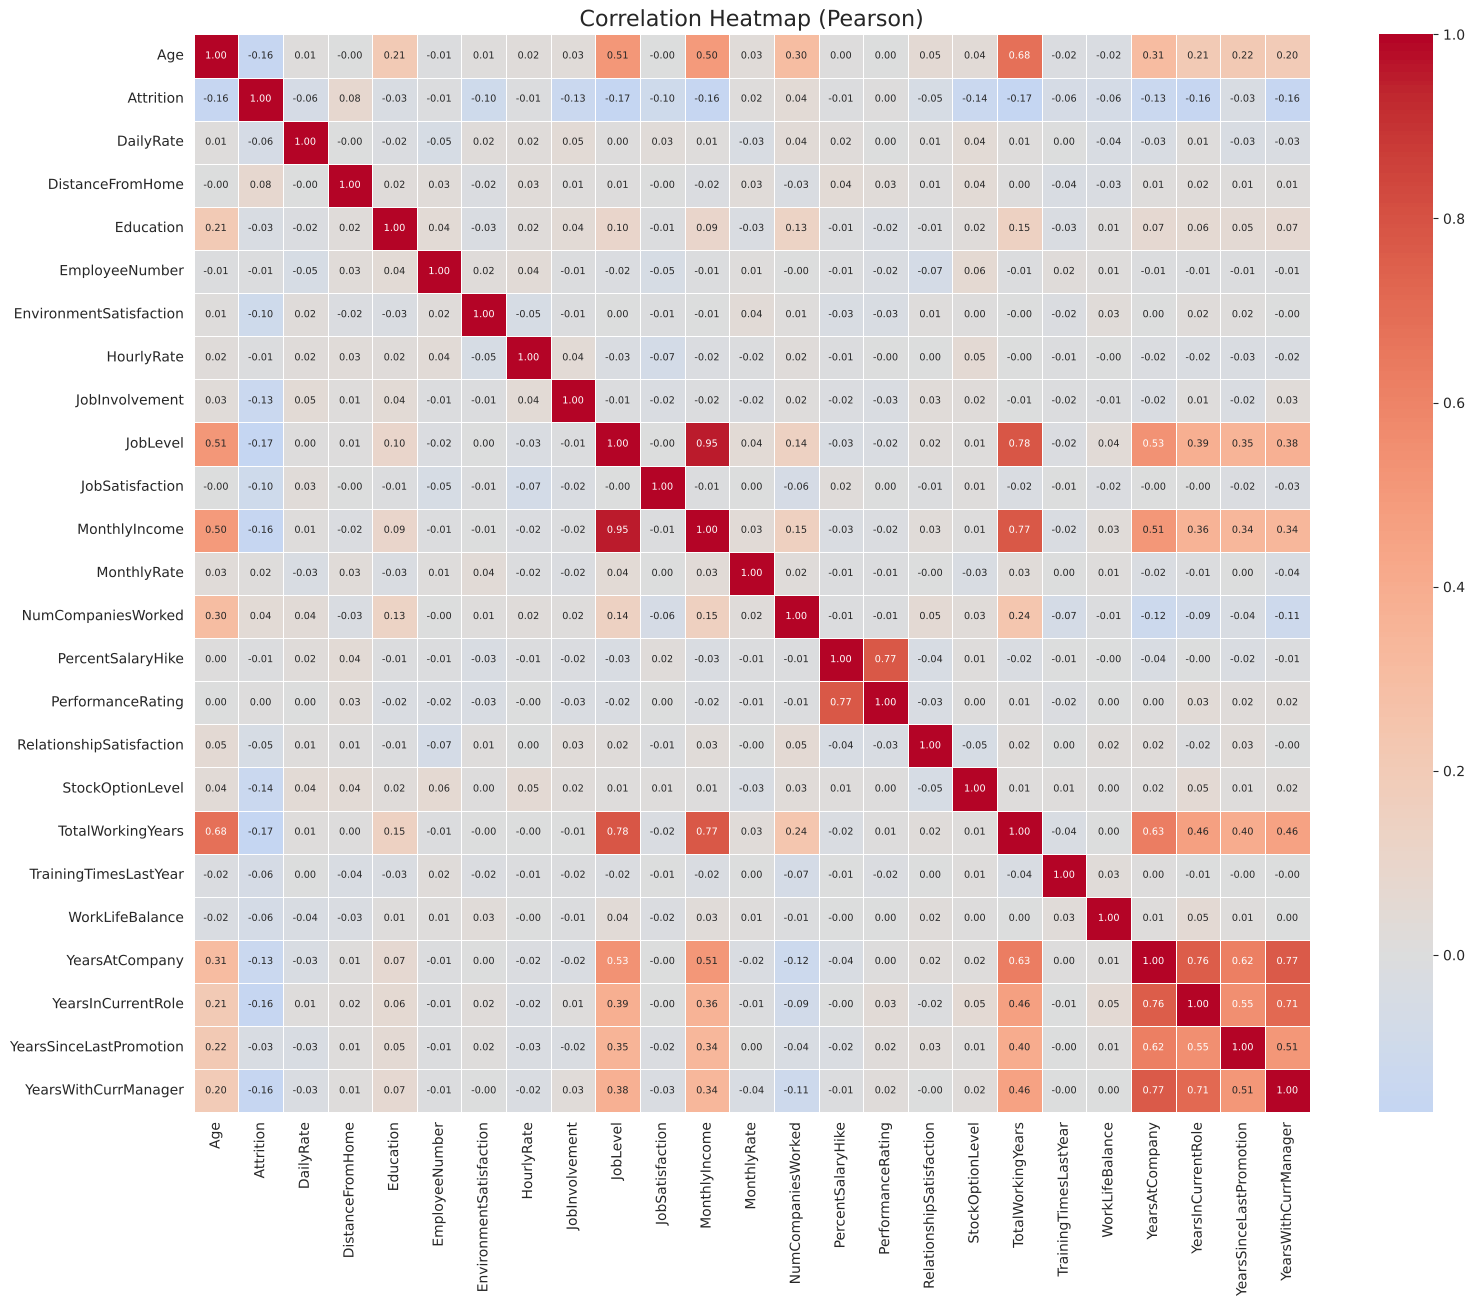

In [13]:
plt.figure(figsize=(18, 14))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            annot_kws={"size": 7}, linewidths=0.5)
plt.title("Correlation Heatmap (Pearson)", fontsize=16)
plt.savefig("figures/05_correlation_heatmap.png", bbox_inches="tight")
plt.show()

**Interpretation:** Strong positive correlations exist between **JobLevel, MonthlyIncome and TotalWorkingYears** (r ≈ 0.77–0.95),
and between **YearsAtCompany, YearsInCurrentRole and YearsWithCurrManager**. Correlations with Attrition are weak individually
(the largest are negative, e.g. TotalWorkingYears, JobLevel, MonthlyIncome), which means attrition depends on many factors together.

### 4.3.6 Pearson correlation coefficient and p-value with Attrition

In [14]:
# Pearson correlation between each numeric feature and Attrition (1 = Yes, 0 = No)
results = []
for col in corr_matrix.columns:
    if col == "Attrition":
        continue
    r, p = stats.pearsonr(df_corr[col], df_corr["Attrition"])
    results.append([col, round(r, 4), p, "Yes" if p < 0.05 else "No"])

pearson_table = pd.DataFrame(results, columns=["Feature", "Pearson r", "p-value", "Significant (p<0.05)"])
pearson_table["abs_r"] = pearson_table["Pearson r"].abs()
pearson_table = pearson_table.sort_values("abs_r", ascending=False).drop(columns="abs_r").reset_index(drop=True)
pearson_table["p-value"] = pearson_table["p-value"].apply(lambda x: f"{x:.2e}")
pearson_table

,Feature,Pearson r,p-value,Significant (p<0.05)
0,TotalWorkingYears,-0.1711,4.06e-11,Yes
1,JobLevel,-0.1691,6.80e-11,Yes
2,YearsInCurrentRole,-0.1605,6.00e-10,Yes
3,MonthlyIncome,-0.1598,7.15e-10,Yes
4,Age,-0.1592,8.36e-10,Yes
5,YearsWithCurrManager,-0.1562,1.74e-09,Yes
6,StockOptionLevel,-0.1371,1.30e-07,Yes
7,YearsAtCompany,-0.1344,2.32e-07,Yes
8,JobInvolvement,-0.1300,5.68e-07,Yes
9,JobSatisfaction,-0.1035,7.04e-05,Yes


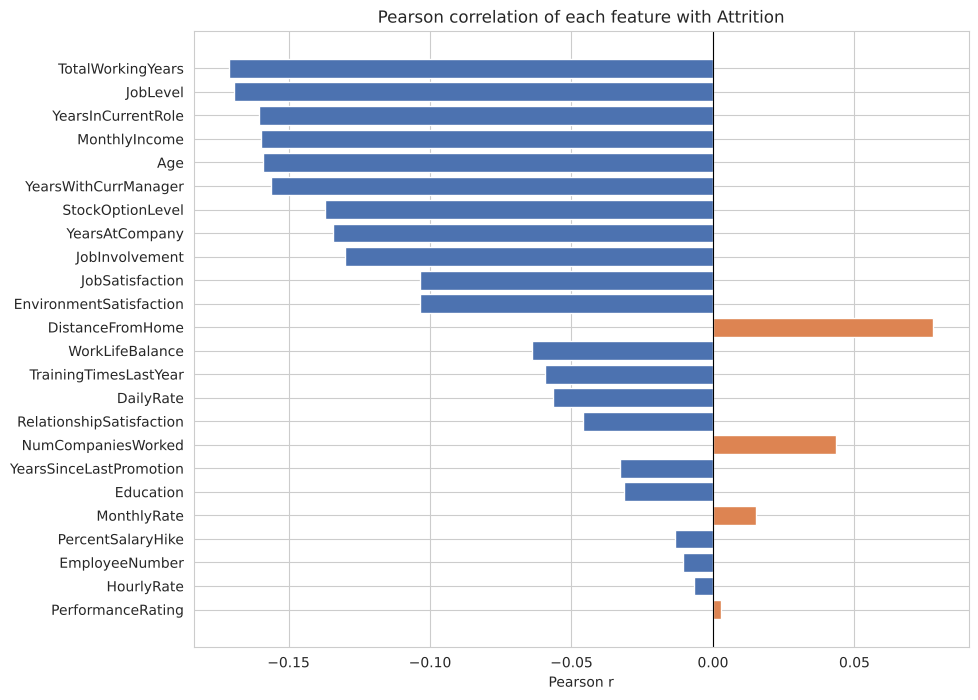

In [15]:
# bar chart of the Pearson r values
plot_data = pearson_table.copy()
colors = ["#DD8452" if v > 0 else "#4C72B0" for v in plot_data["Pearson r"]]

plt.figure(figsize=(10, 8))
plt.barh(plot_data["Feature"], plot_data["Pearson r"], color=colors)
plt.gca().invert_yaxis()
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Pearson correlation of each feature with Attrition")
plt.xlabel("Pearson r")
plt.savefig("figures/06_pearson_with_attrition.png", bbox_inches="tight")
plt.show()

**Interpretation:** Features with **p-value < 0.05** have a statistically significant relationship with attrition.
Negative r means that when the feature increases, attrition decreases (e.g. more working years → less likely to leave).
Features like HourlyRate or PerformanceRating are **not** significant.

### 4.3.7 Regression plots

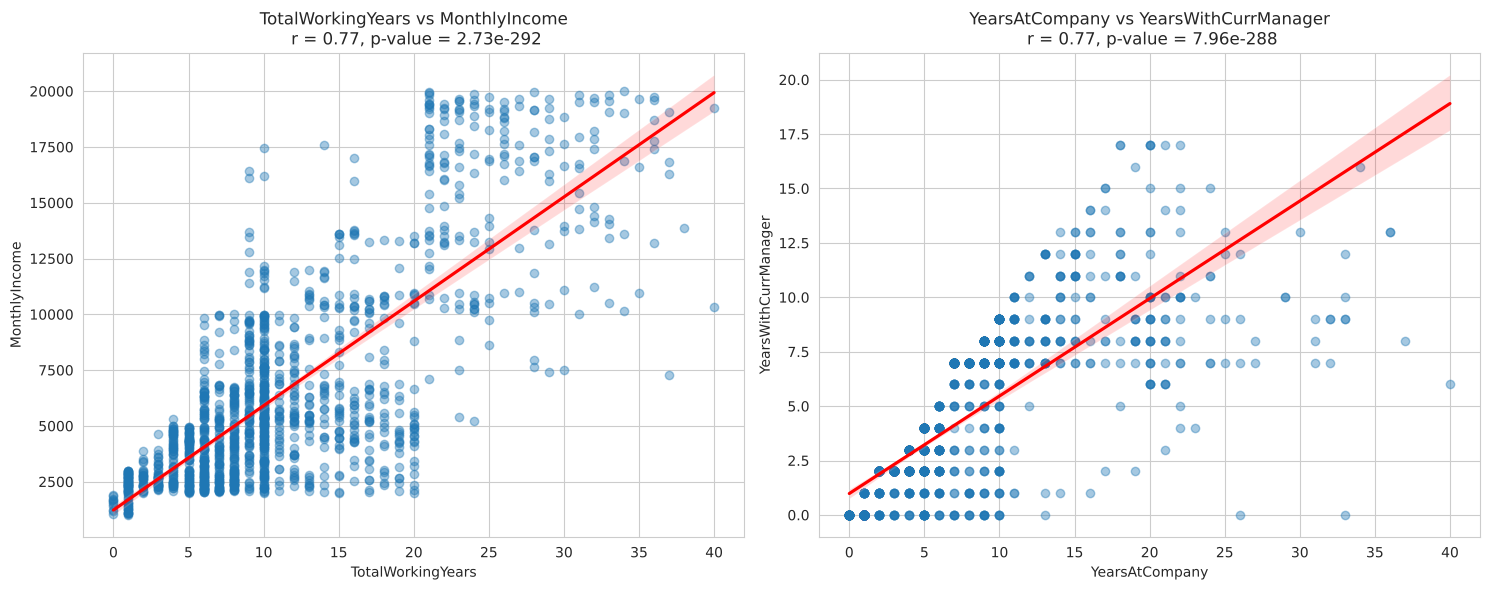

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1) Total working years vs monthly income
sns.regplot(x="TotalWorkingYears", y="MonthlyIncome", data=df, ax=axes[0],
            scatter_kws={"alpha": 0.4}, line_kws={"color": "red"})
r1, p1 = stats.pearsonr(df["TotalWorkingYears"], df["MonthlyIncome"])
axes[0].set_title(f"TotalWorkingYears vs MonthlyIncome\n r = {r1:.2f}, p-value = {p1:.2e}")

# 2) Years at company vs years with current manager
sns.regplot(x="YearsAtCompany", y="YearsWithCurrManager", data=df, ax=axes[1],
            scatter_kws={"alpha": 0.4}, line_kws={"color": "red"})
r2, p2 = stats.pearsonr(df["YearsAtCompany"], df["YearsWithCurrManager"])
axes[1].set_title(f"YearsAtCompany vs YearsWithCurrManager\n r = {r2:.2f}, p-value = {p2:.2e}")

plt.tight_layout()
plt.savefig("figures/07_regression_plots.png", bbox_inches="tight")
plt.show()

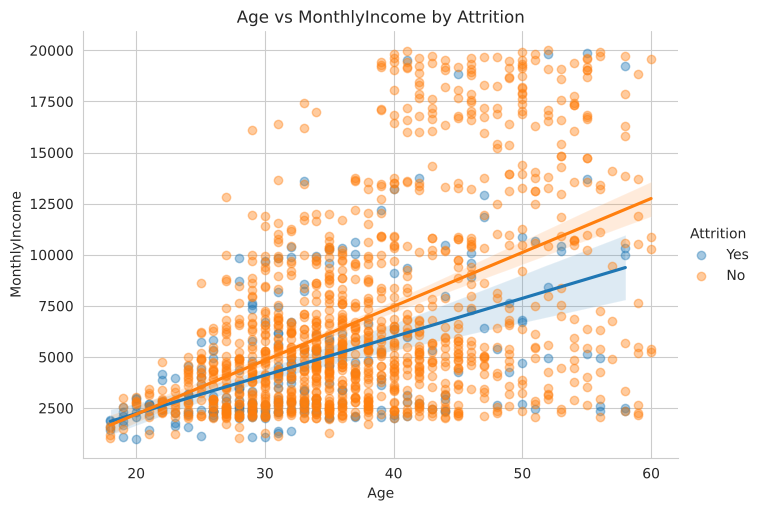

In [17]:
# regression plot split by Attrition
sns.lmplot(x="Age", y="MonthlyIncome", hue="Attrition", data=df, height=5, aspect=1.4,
           scatter_kws={"alpha": 0.4})
plt.title("Age vs MonthlyIncome by Attrition")
plt.savefig("figures/08_regression_by_attrition.png", bbox_inches="tight")
plt.show()

**Interpretation:** There is a strong positive linear relationship between working years and income (r ≈ 0.77, p < 0.05).
In the last plot, employees who left are mostly in the **low income / young age** area.

## 4.4 Data Preprocessing
### 4.4.1 Missing values and duplicates

In [18]:
print("Missing values in each column:")
print(df.isnull().sum())
print()
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows      :", df.duplicated().sum())

Missing values in each column:
Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCu

**Result:** The dataset has **no missing values** and **no duplicate rows**, so no imputation is needed.

### 4.4.2 Feature removal

In [19]:
print("Shape BEFORE removing columns:", df.shape)

for col in ["EmployeeCount", "StandardHours", "Over18", "EmployeeNumber"]:
    print(col, "-> unique values:", df[col].nunique())

Shape BEFORE removing columns: (1470, 35)
EmployeeCount -> unique values: 1
StandardHours -> unique values: 1
Over18 -> unique values: 1
EmployeeNumber -> unique values: 1470


In [20]:
# EmployeeCount, StandardHours and Over18 have the same value for all employees (no information)
# EmployeeNumber is only an ID number
df_clean = df.drop(columns=["EmployeeCount", "StandardHours", "Over18", "EmployeeNumber"])

print("Shape AFTER removing columns:", df_clean.shape)

Shape AFTER removing columns: (1470, 31)


### 4.4.3 Outlier detection and treatment (IQR method)

In [21]:
# find outliers in the numeric columns using the IQR rule
num_cols = df_clean.select_dtypes(include="number").columns

outlier_counts = {}
for col in num_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()
    if n > 0:
        outlier_counts[col] = n

outlier_df = pd.DataFrame.from_dict(outlier_counts, orient="index", columns=["Number of outliers"])
outlier_df["% of rows"] = (outlier_df["Number of outliers"] / len(df_clean) * 100).round(2)
outlier_df.sort_values("Number of outliers", ascending=False)

,Number of outliers,% of rows
TrainingTimesLastYear,238,16.19
PerformanceRating,226,15.37
MonthlyIncome,114,7.76
YearsSinceLastPromotion,107,7.28
YearsAtCompany,104,7.07
StockOptionLevel,85,5.78
TotalWorkingYears,63,4.29
NumCompaniesWorked,52,3.54
YearsInCurrentRole,21,1.43
YearsWithCurrManager,14,0.95


In [22]:
# if we deleted every row that has an outlier, how much data would we lose?
mask = pd.Series(False, index=df_clean.index)
for col in outlier_counts:
    Q1, Q3 = df_clean[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    mask = mask | (df_clean[col] < Q1 - 1.5 * IQR) | (df_clean[col] > Q3 + 1.5 * IQR)

print("Rows that contain at least one outlier:", mask.sum(), f"({mask.mean() * 100:.1f}% of the data)")
print("Attrition = Yes inside those rows     :", (df_clean.loc[mask, "Attrition"] == "Yes").sum())

Rows that contain at least one outlier: 691 (47.0% of the data)
Attrition = Yes inside those rows     : 99


Deleting all these rows would remove a large part of the data (and many "Yes" cases, which are already rare).
The outliers are also **real values** (e.g. senior managers with high salaries), not errors.
So instead of deleting them, we use **capping (winsorization)**: values above the upper limit are replaced by the upper limit,
and values below the lower limit by the lower limit.

In [23]:
cap_cols = ["MonthlyIncome", "TotalWorkingYears", "YearsAtCompany", "YearsInCurrentRole",
            "YearsSinceLastPromotion", "YearsWithCurrManager", "NumCompaniesWorked", "TrainingTimesLastYear"]

df_before_capping = df_clean.copy()
cap_limits = {}   # we save the limits so the app can use the same values

for col in cap_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df_clean[col] = df_clean[col].clip(lower, upper)
    cap_limits[col] = (lower, upper)

print("Shape after capping (no rows removed):", df_clean.shape)

Shape after capping (no rows removed): (1470, 31)


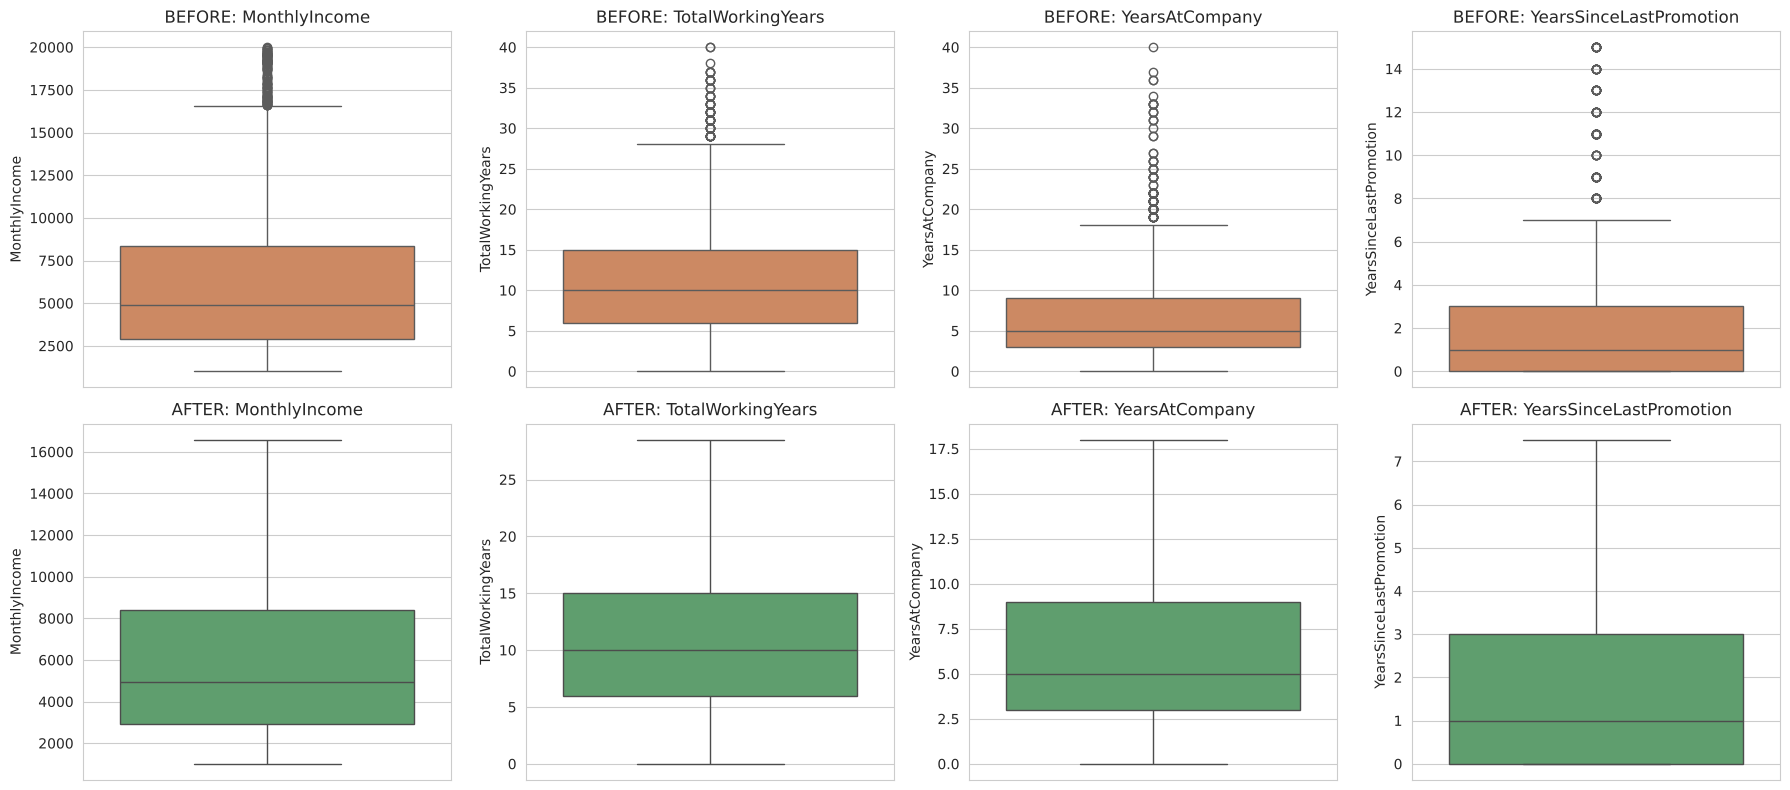

In [24]:
# BEFORE vs AFTER capping
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for i, col in enumerate(["MonthlyIncome", "TotalWorkingYears", "YearsAtCompany", "YearsSinceLastPromotion"]):
    sns.boxplot(y=df_before_capping[col], ax=axes[0, i], color="#DD8452")
    axes[0, i].set_title("BEFORE: " + col)
    sns.boxplot(y=df_clean[col], ax=axes[1, i], color="#55A868")
    axes[1, i].set_title("AFTER: " + col)

plt.tight_layout()
plt.savefig("figures/09_outliers_before_after.png", bbox_inches="tight")
plt.show()

### 4.4.4 Encoding categorical variables

In [25]:
print("BEFORE encoding:")
df_clean[["Attrition", "OverTime", "Gender", "BusinessTravel", "Department", "MaritalStatus"]].head()

BEFORE encoding:


,Attrition,OverTime,Gender,BusinessTravel,Department,MaritalStatus
0,Yes,Yes,Female,Travel_Rarely,Sales,Single
1,No,No,Male,Travel_Frequently,Research & Development,Married
2,Yes,Yes,Male,Travel_Rarely,Research & Development,Single
3,No,Yes,Female,Travel_Frequently,Research & Development,Married
4,No,No,Male,Travel_Rarely,Research & Development,Married


In [26]:
df_encoded = df_clean.copy()

# Label encoding for the binary columns (2 values only)
df_encoded["Attrition"] = df_encoded["Attrition"].map({"Yes": 1, "No": 0})
df_encoded["OverTime"] = df_encoded["OverTime"].map({"Yes": 1, "No": 0})
df_encoded["Gender"] = df_encoded["Gender"].map({"Male": 1, "Female": 0})

# One-hot encoding for columns that have more than 2 categories (no order between them)
multi_cat_cols = ["BusinessTravel", "Department", "EducationField", "JobRole", "MaritalStatus"]
df_encoded = pd.get_dummies(df_encoded, columns=multi_cat_cols, drop_first=True, dtype=int)

print("Shape after encoding:", df_encoded.shape)

Shape after encoding: (1470, 45)


In [27]:
print("AFTER encoding:")
df_encoded.head()

AFTER encoding:


,Age,Attrition,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,...,JobRole_Human Resources,JobRole_Laboratory Technician,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single
0,41,1,1102,1,2,2,0,94,3,2,...,0,0,0,0,0,0,1,0,0,1
1,49,0,279,8,1,3,1,61,2,2,...,0,0,0,0,0,1,0,0,1,0
2,37,1,1373,2,2,4,1,92,2,1,...,0,1,0,0,0,0,0,0,0,1
3,33,0,1392,3,4,4,0,56,3,1,...,0,0,0,0,0,1,0,0,1,0
4,27,0,591,2,1,1,1,40,3,1,...,0,1,0,0,0,0,0,0,1,0


### 4.4.5 Train / test split

In [28]:
X = df_encoded.drop(columns="Attrition")
y = df_encoded["Attrition"]

# 80% training, 20% testing
# stratify=y keeps the same percentage of "Yes" in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print("X_train:", X_train.shape, " X_test:", X_test.shape)
print("Attrition rate in train: {:.2f}%".format(y_train.mean() * 100))
print("Attrition rate in test : {:.2f}%".format(y_test.mean() * 100))

X_train: (1176, 44)  X_test: (294, 44)
Attrition rate in train: 16.16%
Attrition rate in test : 15.99%


### 4.4.6 Feature scaling (StandardScaler)

In [29]:
print("BEFORE scaling:")
X_train[["Age", "MonthlyIncome", "DailyRate", "DistanceFromHome", "TotalWorkingYears"]].describe().round(2)

BEFORE scaling:


,Age,MonthlyIncome,DailyRate,DistanceFromHome,TotalWorkingYears
count,1176.00,1176.00,1176.00,1176.00,1176.00
mean,37.00,6417.08,803.99,9.36,11.19
std,9.18,4334.43,401.34,8.18,7.33
min,18.00,1009.00,103.00,1.00,0.00
25%,30.00,2948.00,467.75,2.00,6.00
50%,36.00,5004.50,799.50,7.00,10.00
75%,43.00,8420.50,1157.00,14.00,15.00
max,60.00,16581.00,1499.00,29.00,28.50


In [30]:
scaler = StandardScaler()

# fit only on the training data, then apply to the test data (to avoid data leakage)
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

print("AFTER scaling (mean = 0, std = 1):")
X_train_scaled[["Age", "MonthlyIncome", "DailyRate", "DistanceFromHome", "TotalWorkingYears"]].describe().round(2)

AFTER scaling (mean = 0, std = 1):


,Age,MonthlyIncome,DailyRate,DistanceFromHome,TotalWorkingYears
count,1176.00,1176.00,1176.00,1176.00,1176.00
mean,-0.00,0.00,0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00,1.00
min,-2.07,-1.25,-1.75,-1.02,-1.53
25%,-0.76,-0.80,-0.84,-0.90,-0.71
50%,-0.11,-0.33,-0.01,-0.29,-0.16
75%,0.65,0.46,0.88,0.57,0.52
max,2.51,2.35,1.73,2.40,2.36


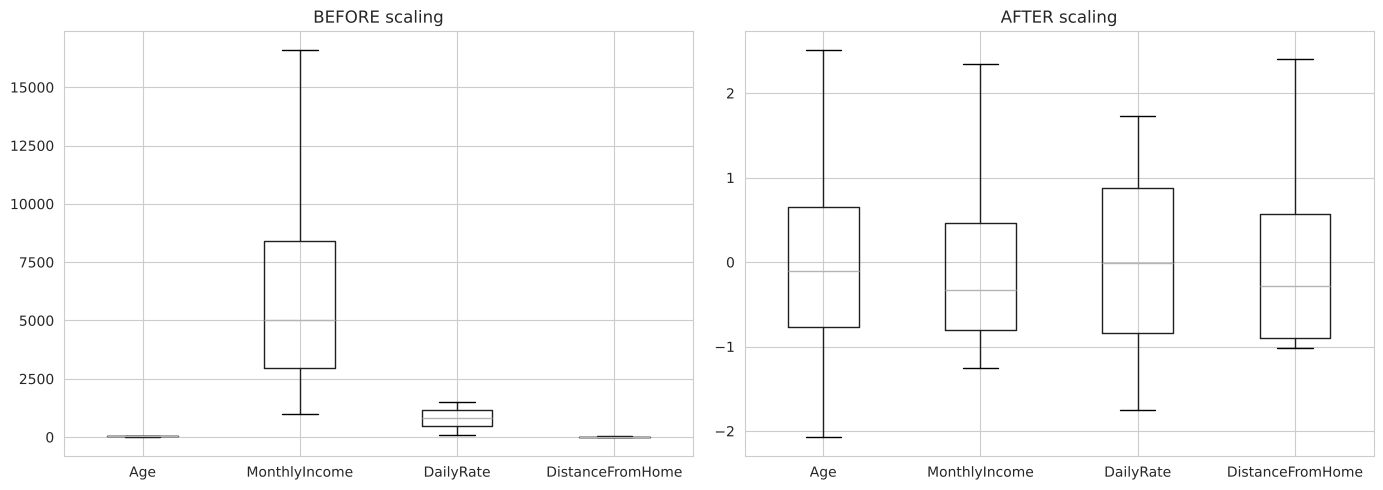

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
X_train[["Age", "MonthlyIncome", "DailyRate", "DistanceFromHome"]].boxplot(ax=axes[0])
axes[0].set_title("BEFORE scaling")
X_train_scaled[["Age", "MonthlyIncome", "DailyRate", "DistanceFromHome"]].boxplot(ax=axes[1])
axes[1].set_title("AFTER scaling")
plt.tight_layout()
plt.savefig("figures/10_scaling_before_after.png", bbox_inches="tight")
plt.show()

## 4.5 Model Building
We use two models (chosen based on the literature review):

- **Logistic Regression** – simple, fast and easy to interpret (baseline model)
- **Random Forest** – an ensemble of decision trees that can learn non-linear relationships

Because the data is imbalanced we use `class_weight="balanced"`, which gives more weight to the "Yes" class.

### 4.5.1 Baseline models (default parameters)

In [32]:
# helper function to calculate the metrics of a model
def evaluate(model, X_te, y_te, name):
    y_pred = model.predict(X_te)
    y_prob = model.predict_proba(X_te)[:, 1]
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_te, y_pred),
        "Precision": precision_score(y_te, y_pred),
        "Recall": recall_score(y_te, y_pred),
        "F1-score": f1_score(y_te, y_pred),
        "ROC-AUC": roc_auc_score(y_te, y_prob),
    }

In [33]:
# Logistic Regression (default)
lr_base = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
lr_base.fit(X_train_scaled, y_train)

# Random Forest (default)
rf_base = RandomForestClassifier(random_state=RANDOM_STATE)
rf_base.fit(X_train_scaled, y_train)

baseline_results = pd.DataFrame([
    evaluate(lr_base, X_test_scaled, y_test, "Logistic Regression (baseline)"),
    evaluate(rf_base, X_test_scaled, y_test, "Random Forest (baseline)"),
]).round(4)
baseline_results

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression (baseline),0.8571,0.6,0.3191,0.4167,0.8027
1,Random Forest (baseline),0.8333,0.4,0.0851,0.1404,0.7838


**Observation:** Accuracy looks good, but the **Recall** for the "Yes" class is low (especially for Random Forest),
which means the models miss many employees who actually leave. We improve this with class weights and hyperparameter tuning.

### 4.5.2 Hyperparameter tuning with GridSearchCV (5-fold cross validation)

In [34]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# ---- Logistic Regression ----
lr_params = {
    "C": [0.01, 0.1, 0.5, 1, 5, 10],
    "penalty": ["l1", "l2"],
    "solver": ["liblinear"],
    "class_weight": ["balanced"],
}

lr_grid = GridSearchCV(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
                       lr_params, scoring="f1", cv=cv, n_jobs=-1)
lr_grid.fit(X_train_scaled, y_train)

print("Best Logistic Regression parameters:", lr_grid.best_params_)
print("Best cross-validation F1-score     : {:.4f}".format(lr_grid.best_score_))

Best Logistic Regression parameters: {'C': 0.5, 'class_weight': 'balanced', 'penalty': 'l2', 'solver': 'liblinear'}
Best cross-validation F1-score     : 0.5002


In [35]:
# ---- Random Forest ----
rf_params = {
    "n_estimators": [100, 300],
    "max_depth": [5, 10, None],
    "min_samples_leaf": [1, 3, 5],
    "max_features": ["sqrt", 0.3],
    "class_weight": ["balanced", "balanced_subsample"],
}

rf_grid = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE),
                       rf_params, scoring="f1", cv=cv, n_jobs=-1)
rf_grid.fit(X_train_scaled, y_train)

print("Best Random Forest parameters:", rf_grid.best_params_)
print("Best cross-validation F1-score: {:.4f}".format(rf_grid.best_score_))

Best Random Forest parameters: {'class_weight': 'balanced', 'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'n_estimators': 100}
Best cross-validation F1-score: 0.4987


In [36]:
lr_best = lr_grid.best_estimator_
rf_best = rf_grid.best_estimator_

### 4.5.3 Feature importance

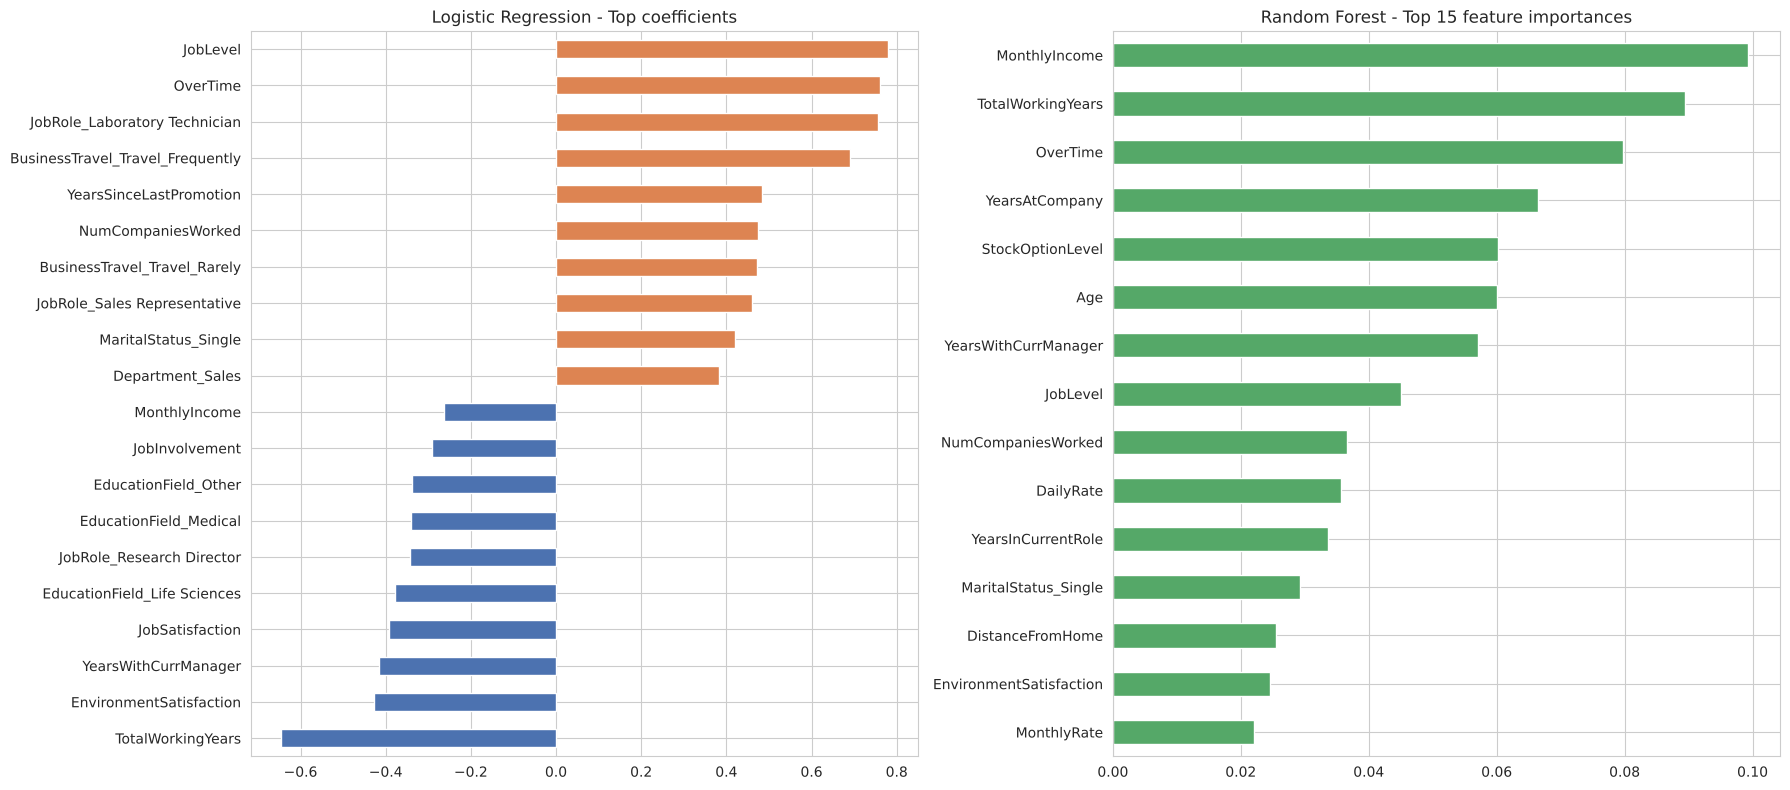

In [37]:
# Logistic Regression coefficients (positive = increases the chance of leaving)
lr_coef = pd.Series(lr_best.coef_[0], index=X_train.columns).sort_values()
top_coef = pd.concat([lr_coef.head(10), lr_coef.tail(10)])

# Random Forest feature importance
rf_imp = pd.Series(rf_best.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(15)

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
top_coef.plot(kind="barh", ax=axes[0], color=["#4C72B0" if v < 0 else "#DD8452" for v in top_coef])
axes[0].set_title("Logistic Regression - Top coefficients")
rf_imp.sort_values().plot(kind="barh", ax=axes[1], color="#55A868")
axes[1].set_title("Random Forest - Top 15 feature importances")
plt.tight_layout()
plt.savefig("figures/11_feature_importance.png", bbox_inches="tight")
plt.show()

**Interpretation:** Both models agree that **OverTime**, income, age/experience and satisfaction-related features are
among the most important factors for attrition.

## 4.6 Evaluation & Results
### 4.6.1 Comparison table

In [38]:
results = pd.DataFrame([
    evaluate(lr_base, X_test_scaled, y_test, "Logistic Regression (baseline)"),
    evaluate(rf_base, X_test_scaled, y_test, "Random Forest (baseline)"),
    evaluate(lr_best, X_test_scaled, y_test, "Logistic Regression (tuned)"),
    evaluate(rf_best, X_test_scaled, y_test, "Random Forest (tuned)"),
]).round(4)

results.to_csv("model/results.csv", index=False)
results

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression (baseline),0.8571,0.6000,0.3191,0.4167,0.8027
1,Random Forest (baseline),0.8333,0.4000,0.0851,0.1404,0.7838
2,Logistic Regression (tuned),0.7517,0.3488,0.6383,0.4511,0.7931
3,Random Forest (tuned),0.7993,0.4167,0.6383,0.5042,0.7623


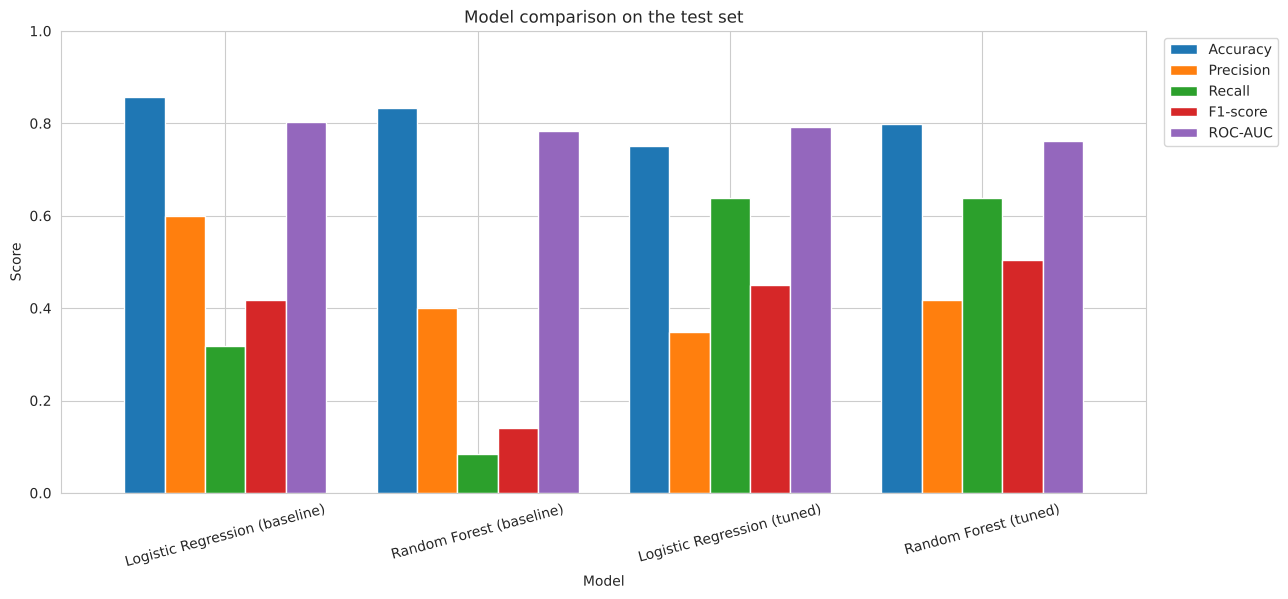

In [39]:
# bar chart comparing the 4 models
results_plot = results.set_index("Model")[["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]]
results_plot.plot(kind="bar", figsize=(14, 6), width=0.8)
plt.title("Model comparison on the test set")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.savefig("figures/12_model_comparison.png", bbox_inches="tight")
plt.show()

### 4.6.2 Confusion matrices

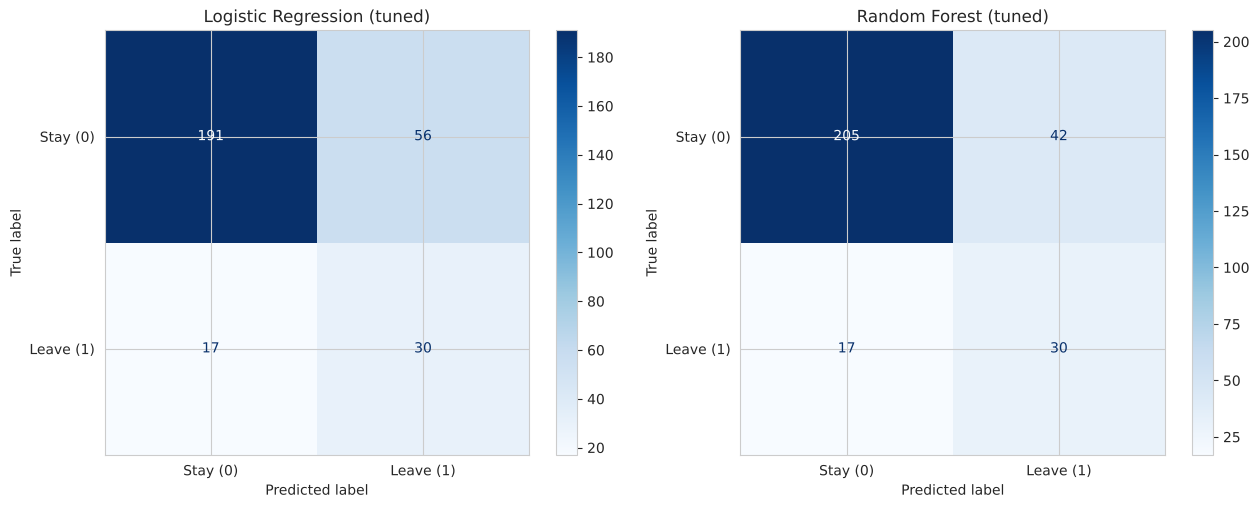

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, model, name in zip(axes, [lr_best, rf_best], ["Logistic Regression (tuned)", "Random Forest (tuned)"]):
    ConfusionMatrixDisplay.from_estimator(model, X_test_scaled, y_test,
                                          display_labels=["Stay (0)", "Leave (1)"], cmap="Blues", ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.savefig("figures/13_confusion_matrices.png", bbox_inches="tight")
plt.show()

In [41]:
print("=== Logistic Regression (tuned) ===")
print(classification_report(y_test, lr_best.predict(X_test_scaled), target_names=["Stay", "Leave"]))
print("=== Random Forest (tuned) ===")
print(classification_report(y_test, rf_best.predict(X_test_scaled), target_names=["Stay", "Leave"]))

=== Logistic Regression (tuned) ===
              precision    recall  f1-score   support

        Stay       0.92      0.77      0.84       247
       Leave       0.35      0.64      0.45        47

    accuracy                           0.75       294
   macro avg       0.63      0.71      0.65       294
weighted avg       0.83      0.75      0.78       294

=== Random Forest (tuned) ===
              precision    recall  f1-score   support

        Stay       0.92      0.83      0.87       247
       Leave       0.42      0.64      0.50        47

    accuracy                           0.80       294
   macro avg       0.67      0.73      0.69       294
weighted avg       0.84      0.80      0.82       294



### 4.6.3 ROC curves

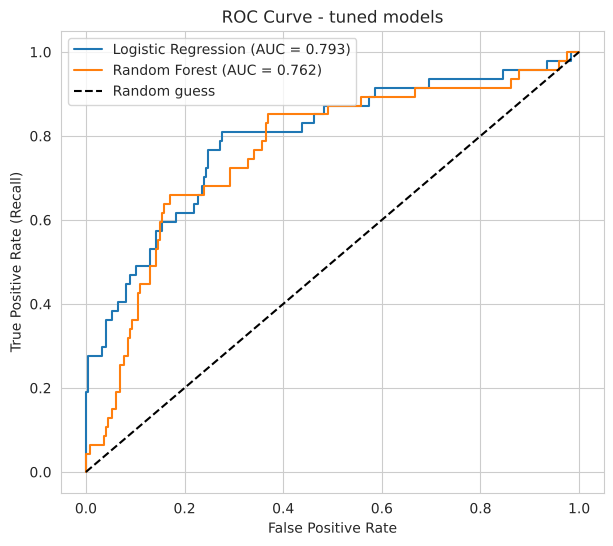

In [42]:
plt.figure(figsize=(7, 6))
for model, name in [(lr_best, "Logistic Regression"), (rf_best, "Random Forest")]:
    y_prob = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, y_prob):.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve - tuned models")
plt.legend()
plt.savefig("figures/14_roc_curves.png", bbox_inches="tight")
plt.show()

### 4.6.4 Best model

In [43]:
# we choose the best model using the F1-score because the data is imbalanced
tuned = results[results["Model"].str.contains("tuned")]
best_row = tuned.loc[tuned["F1-score"].idxmax()]
print("Best model:", best_row["Model"])
print(best_row)

best_model = lr_best if "Logistic" in best_row["Model"] else rf_best

Best model: Random Forest (tuned)
Model        Random Forest (tuned)
Accuracy                    0.7993
Precision                   0.4167
Recall                      0.6383
F1-score                    0.5042
ROC-AUC                     0.7623
Name: 3, dtype: object


**Justification:** (write it after you see your numbers) – the best model is the one with the highest **F1-score and Recall**
for the "Leave" class, because for HR it is more costly to miss an employee who will leave (False Negative)
than to wrongly flag an employee who will stay (False Positive).

### 4.6.5 Save the model for the Streamlit app

In [44]:
# default values for every original column (median for numbers, most common value for text)
defaults = {}
for col in df_clean.columns:
    if col == "Attrition":
        continue
    if pd.api.types.is_numeric_dtype(df_clean[col]):
        defaults[col] = float(df_clean[col].median())
    else:
        defaults[col] = df_clean[col].mode()[0]

# all the categories of each text column (for the drop-down lists in the app)
categories = {col: sorted(df_clean[col].unique().tolist()) for col in df_clean.columns
              if not pd.api.types.is_numeric_dtype(df_clean[col]) and col != "Attrition"}

joblib.dump({
    "model": best_model,
    "model_name": best_row["Model"],
    "scaler": scaler,
    "columns": X_train.columns.tolist(),
    "cap_limits": cap_limits,
    "multi_cat_cols": multi_cat_cols,
    "defaults": defaults,
    "categories": categories,
}, "model/attrition_model.pkl")

print("Model saved to model/attrition_model.pkl")

Model saved to model/attrition_model.pkl


In [45]:
# quick test: predict the first 5 employees of the test set
sample = X_test_scaled.head(5)
pred = best_model.predict(sample)
prob = best_model.predict_proba(sample)[:, 1]
pd.DataFrame({"Actual": y_test.head(5).values, "Predicted": pred, "Probability of leaving": prob.round(3)})

,Actual,Predicted,Probability of leaving
0,0,1,0.797
1,0,0,0.266
2,0,0,0.349
3,0,0,0.157
4,1,1,0.557
